# 03 — Are user-defined gestures unique? (model-free, all 32 users)

This is a dataset analysis with no training and no model selection, so it uses all 32 users. It tests the premise the paper rests on (study plan `docs/10_23_26_encodermoe_study_plan.md`, H1/H2):

| Part | Question | Null / chance |
|---|---|---|
| A | **Cross-user zero-shot.** Classify each trial of user *u* by nearest *label centroid* built from the other 31 users. Compare with within-user 1-shot. | 10% |
| B | **Label agreement.** For each gesture prototype p(u,g) (mean of 10 reps), is its nearest other-user prototype the *same label*? | 10%, plus a label permutation |
| C | **Motifs.** How many other-user prototypes (any label) are as close to p(u,g) as u's own reps are? | channel-permuted other users |
| D | **Ability.** Do users in the same ability group share more motifs? Mantel test of the user x user motif matrix against same-group membership. | 10k user permutations |

**Pre-stated readings.**
- High A or B (well above chance) means labels carry shared semantics, so the "user-defined" framing must soften (compare `SPEC_zeroshot.md` thresholds).
- Near-chance B with C above null means executions recur across users *under different labels*. That is the sample-level motif story.
- D > 0 supports the ability story. With 32 users, report r and p and do not overinterpret.

**Features (fixed before running).**
- Each user's channels are standardised over that user's 100 trials. This removes per-user gain and placement scale, so "similar" means similar *shape*.
- Per channel: the mean over 4 equal time segments plus the std over time, giving 5 numbers per channel. This tolerates small timing differences.
- Modalities are analysed separately (IMU, EMG fs64, EMG env20) and together (each block scaled to equal weight).
- Caveat: env20 and the dict IMU carry the open time-axis anomaly. Segment means are fairly robust to it, but treat env20 with care.

In [1]:
import os, sys, pickle, json
from pathlib import Path
import numpy as np

REPO = Path.cwd()
while not (REPO / ".git").exists():
    REPO = REPO.parent
os.chdir(REPO)
for rel in ("system", "system/MAML"):
    sys.path.insert(0, str(REPO / rel))
os.environ.setdefault("CODE_DIR", str(REPO))
os.environ.setdefault("RUN_DIR", os.environ.get("TEMP", "/tmp"))
os.environ.setdefault("HPO_CONFIG", "legacy")

from episodes import episode_cache as ec
from episodes.episode_numpy import materialize
from MAML.maml_data_pipeline import reorient_tensor_dict

DS = REPO / "dataset" / "meta-learning-sup-que-ds"
def load_dict(name, emg_ch):
    d = pickle.load(open(DS / name, "rb"))
    return d, reorient_tensor_dict(d, {"emg_in_ch": emg_ch, "imu_in_ch": 72})   # -> (trials, C, T)


In [2]:
import pandas as pd
d20, td20 = load_dict("segfilt_rts_tensor_dict.pkl", 16)
d64, td64 = load_dict("segfilt_fs64_tensor_dict.pkl", 112)
split = json.load(open(REPO / "system/fixed_user_splits/kfold28_hpo4_split.json"))
GROUP = {u: g for g, us in split["groups"].items() for u in us}
USERS = sorted(td20)
G = 10
assert set(USERS) == set(GROUP), "every user needs an ability group"

def feats(x, n_seg=4):
    """(trials, C, T) -> (trials, C, n_seg + 1): segment means + std over time, per channel."""
    segs = np.array_split(x, n_seg, axis=2)
    return np.concatenate([np.stack([s.mean(2) for s in segs], 2), x.std(2)[..., None]], 2)

def user_block(td, key, u):
    """-> (G, 10, C*F) per-user standardised features for one modality."""
    x = np.stack([td[u][g][key].numpy() for g in range(G)]).astype(np.float64)   # (G, R, C, T)
    Gn, R, C, T = x.shape
    flat = x.reshape(Gn * R, C, T)
    mu = flat.mean((0, 2), keepdims=True); sd = flat.std((0, 2), keepdims=True) + 1e-8
    f = feats((flat - mu) / sd)                                                   # (G*R, C, F)
    return f.reshape(Gn, R, C, -1)

MODS = {"imu": (td20, "imu"), "emg_fs64": (td64, "emg"), "emg_env20": (td20, "emg")}
RAW = {m: {u: user_block(td, k, u) for u in USERS} for m, (td, k) in MODS.items()}   # (G, R, C, F)

def flat_feats(mods, u, perm=None):
    """(G, R, D) with each modality block scaled to equal weight; perm = channel permutation per modality."""
    parts = []
    for m in mods:
        x = RAW[m][u]
        if perm is not None:
            x = x[:, :, perm[m]]
        x = x.reshape(x.shape[0], x.shape[1], -1)
        parts.append(x / np.sqrt(x.shape[2]))
    return np.concatenate(parts, 2)

SETS = {"IMU": ["imu"], "EMG fs64": ["emg_fs64"], "EMG env20": ["emg_env20"], "IMU + EMG fs64": ["imu", "emg_fs64"]}
X = {s: {u: flat_feats(m, u) for u in USERS} for s, m in SETS.items()}
print({s: X[s][USERS[0]].shape for s in X})

C:\Users\kdmen\anaconda3\envs\fl_torch\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.2.0 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


{'IMU': (10, 10, 360), 'EMG fs64': (10, 10, 560), 'EMG env20': (10, 10, 80), 'IMU + EMG fs64': (10, 10, 920)}


## A. Cross-user zero-shot vs within-user 1-shot

In [3]:
def zero_shot(Xs):
    acc = {}
    for u in USERS:
        others = np.stack([Xs[v].mean(1) for v in USERS if v != u])     # (31, G, D) prototypes
        cent = others.mean(0)                                             # (G, D) label centroids
        q = Xs[u].reshape(-1, Xs[u].shape[-1]); y = np.repeat(np.arange(G), Xs[u].shape[1])
        acc[u] = ((q[:, None] - cent[None]) ** 2).sum(2).argmin(1).__eq__(y).mean()
    return acc

def within_1shot(Xs, n_draw=50, seed=0):
    rng = np.random.default_rng(seed); acc = {}
    for u in USERS:
        x = Xs[u]; R = x.shape[1]; a = []
        for _ in range(n_draw):
            sup = rng.integers(R, size=G)
            P = x[np.arange(G), sup]
            mask = np.ones((G, R), bool); mask[np.arange(G), sup] = False
            q = x[mask]; y = np.repeat(np.arange(G), R)[mask.ravel()]
            a.append((((q[:, None] - P[None]) ** 2).sum(2).argmin(1) == y).mean())
        acc[u] = float(np.mean(a))
    return acc

rows = {}
for s in X:
    zs, w1 = zero_shot(X[s]), within_1shot(X[s])
    rows[s] = {"cross-user zero-shot %": 100 * np.mean(list(zs.values())),
               "within-user 1-shot %": 100 * np.mean(list(w1.values())),
               "users with zero-shot > 20%": sum(v > 0.2 for v in zs.values())}
pd.DataFrame(rows).T.round(1)

,cross-user zero-shot %,within-user 1-shot %,users with zero-shot > 20%
IMU,15.6,67.9,8.0
EMG fs64,12.8,75.9,7.0
EMG env20,12.6,62.1,4.0
IMU + EMG fs64,15.2,78.0,8.0


## B. Label agreement of the nearest other-user prototype

In [4]:
def label_agreement(Xs, n_perm=1000, seed=0):
    P = {u: Xs[u].mean(1) for u in USERS}                               # (G, D)
    nn = []                                                              # (u, g, v*, h*) nearest other-user prototype
    for u in USERS:
        others = [v for v in USERS if v != u]
        allP = np.concatenate([P[v] for v in others])                    # (31*G, D)
        k = ((P[u][:, None] - allP[None]) ** 2).sum(2).argmin(1)
        nn += [(g, others[i // G], i % G) for g, i in enumerate(k)]
    obs = float(np.mean([h == g for g, v, h in nn]))
    rng = np.random.default_rng(seed); null = []
    for _ in range(n_perm):          # relabel each other user's gestures at random
        rl = {v: rng.permutation(G) for v in USERS}
        null.append(np.mean([rl[v][h] == g for g, v, h in nn]))
    return obs, float(np.mean(null)), float((np.sum(np.array(null) >= obs) + 1) / (n_perm + 1))

rows = {}
for s in X:
    obs, nm, p = label_agreement(X[s], n_perm=1000)
    rows[s] = {"same-label NN %": 100 * obs, "null mean %": 100 * nm, "perm p": p}
pd.DataFrame(rows).T.round(3)

,same-label NN %,null mean %,perm p
IMU,18.750,9.939,0.001
EMG fs64,13.438,9.915,0.035
EMG env20,15.313,10.066,0.002
IMU + EMG fs64,16.562,9.921,0.001


## C. Motif matches vs a channel-permutation null, and D. ability (Mantel)

In [5]:
def motif_matrix(mods, perm_seed=None, q=90):
    rng = np.random.default_rng(perm_seed) if perm_seed is not None else None
    Xs = {u: flat_feats(mods, u) for u in USERS}
    P = {u: Xs[u].mean(1) for u in USERS}
    # threshold per (u, g): q-th percentile of u's own rep-to-prototype distances
    thr = {u: np.percentile(((Xs[u] - P[u][:, None]) ** 2).sum(2), q, axis=1) for u in USERS}
    M = np.zeros((len(USERS), len(USERS))); same_label = 0; total = 0
    for i, u in enumerate(USERS):
        for j, v in enumerate(USERS):
            if u == v:
                continue
            if rng is not None:   # destroy spatial structure of the OTHER user, keep amplitude stats
                perm = {m: rng.permutation(RAW[m][v].shape[2]) for m in mods}
                Pv = flat_feats(mods, v, perm).mean(1)
            else:
                Pv = P[v]
            d = ((P[u][:, None] - Pv[None]) ** 2).sum(2)                   # (G, G)
            match = d <= thr[u][:, None]
            M[i, j] = match.sum()
            same_label += np.trace(match); total += match.sum()
    return M, same_label / max(total, 1)

def mantel(M, n_perm=10000, seed=0):
    S = (M + M.T) / 2
    grp = np.array([GROUP[u] for u in USERS])
    A = (grp[:, None] == grp[None]).astype(float)
    iu = np.triu_indices(len(USERS), 1)
    r_obs = np.corrcoef(S[iu], A[iu])[0, 1]
    rng = np.random.default_rng(seed); null = []
    for _ in range(n_perm):
        p = rng.permutation(len(USERS))
        null.append(np.corrcoef(S[iu], A[p][:, p][iu])[0, 1])
    return float(r_obs), float((np.sum(np.array(null) >= r_obs) + 1) / (n_perm + 1))

rows = {}
for s, mods in SETS.items():
    M, frac_same = motif_matrix(mods)
    Mn, _ = motif_matrix(mods, perm_seed=1)
    r, p = mantel(M)
    rows[s] = {"matches / prototype": M.sum() / (len(USERS) * G),
               "null (channel-permuted)": Mn.sum() / (len(USERS) * G),
               "same-label share of matches %": 100 * frac_same,
               "Mantel r (same ability group)": r, "Mantel p": p}
    if s == "IMU + EMG fs64":
        M_fused = M
pd.DataFrame(rows).T.round(3)

,matches / prototype,null (channel-permuted),same-label share of matches %,Mantel r (same ability group),Mantel p
IMU,30.228,21.375,10.224,0.053,0.166
EMG fs64,13.191,6.794,10.424,0.090,0.051
EMG env20,54.672,49.709,10.374,-0.010,0.550
IMU + EMG fs64,11.194,6.719,10.357,0.072,0.104


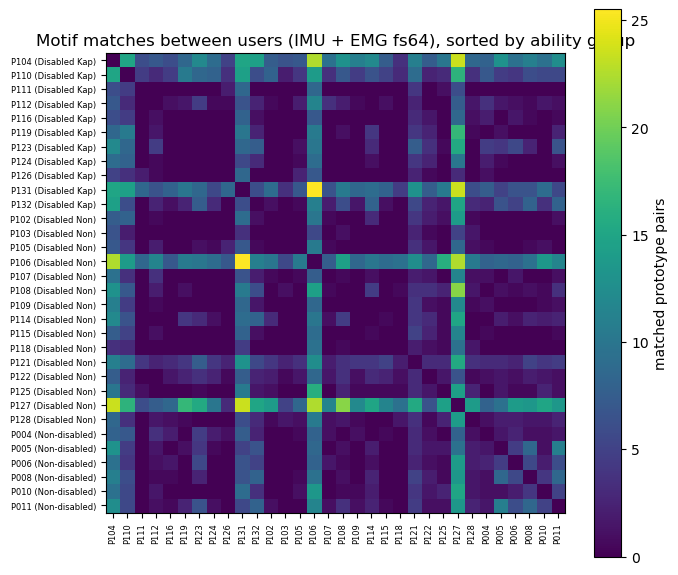

In [6]:
import matplotlib.pyplot as plt
order = sorted(USERS, key=lambda u: (GROUP[u], u))
idx = [USERS.index(u) for u in order]
S = (M_fused + M_fused.T) / 2
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(S[np.ix_(idx, idx)], cmap="viridis")
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=90, fontsize=6)
ax.set_yticks(range(len(order))); ax.set_yticklabels([f"{u} ({GROUP[u][:12]})" for u in order], fontsize=6)
ax.set_title("Motif matches between users (IMU + EMG fs64), sorted by ability group")
fig.colorbar(im, ax=ax, label="matched prototype pairs"); plt.tight_layout(); plt.show()